# Socioeconomic & Education Analysis

## Project Overview

This project investigates the relationship between socioeconomic and educational indicators and Universal Health Coverage (UHC) across countries and years.

The analysis focuses on three main relationships:

1. GDP Per Capita (PPP) and UHC Service Coverage.
2. Secondary School Enrollment and UHC Service Coverage.
3. Adult Literacy Rate and UHC Service Coverage.

## Research Objectives

- Understand the structure and quality of the integrated dataset.
- Explore the distributions of the selected indicators.
- Measure statistical associations between socioeconomic indicators and healthcare coverage.
- Examine how these relationships vary over time.
- Identify important findings and limitations to support the final dashboard.

## Data Source

The analysis uses the original `integrated_healthcare_dataset.csv` file without modifying its contents.

## Methodology

The analysis uses descriptive statistics, exploratory data analysis, visualizations, and correlation analysis. Missing values are handled separately for each comparison, and correlation is not interpreted as causation.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define project paths

PROJECT_DIR = Path.cwd().parent

DATA_PATH = PROJECT_DIR / "data" / "integrated_healthcare_dataset.csv"

OUTPUT_DIR = PROJECT_DIR / "outputs"
CHARTS_DIR = OUTPUT_DIR / "Charts"

# Create output folders if they do not exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]:,}")

Dataset loaded successfully!
Number of rows: 12,855
Number of columns: 27


In [3]:
# Display first 5 rows
display(df.head())

# Display all column names
print("\nDataset Columns:")
for column in df.columns:
    print(column)

,ISO3,Country,Year,Population,Age_0_14_Pct,Age_65_Plus_Pct,Urban_Population_Pct,GDP_Per_Capita_PPP_2021,Secondary_Enrollment_Gross_Pct,Adult_Literacy_Rate,Doctors_Total,Doctors_Per_10k,Nurses_Midwives_Per_10k,Hospital_Beds_Per_10k,UHC_Service_Coverage_Index,Health_Exp_Per_Capita_PPP,Health_Exp_Pct_GDP,OOP_Pct_Current_Health_Exp,Financial_Hardship_Total_Pct,Large_Spending_Pct,Impoverishing_Spending_Pct,Q1_Poorest_Pct,Q2_Pct,Q3_Pct,Q4_Pct,Q5_Richest_Pct,Equity_Gap_Pct_Points
0,AFG,Afghanistan,1960,"9,035,043.00",41.95,2.82,8.12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AFG,Afghanistan,1961,"9,214,083.00",42.03,2.81,8.39,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AFG,Afghanistan,1962,"9,404,406.00",42.11,2.79,8.66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AFG,Afghanistan,1963,"9,604,487.00",42.24,2.78,8.94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AFG,Afghanistan,1964,"9,814,318.00",42.41,2.76,9.23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Dataset Columns:
ISO3
Country
Year
Population
Age_0_14_Pct
Age_65_Plus_Pct
Urban_Population_Pct
GDP_Per_Capita_PPP_2021
Secondary_Enrollment_Gross_Pct
Adult_Literacy_Rate
Doctors_Total
Doctors_Per_10k
Nurses_Midwives_Per_10k
Hospital_Beds_Per_10k
UHC_Service_Coverage_Index
Health_Exp_Per_Capita_PPP
Health_Exp_Pct_GDP
OOP_Pct_Current_Health_Exp
Financial_Hardship_Total_Pct
Large_Spending_Pct
Impoverishing_Spending_Pct
Q1_Poorest_Pct
Q2_Pct
Q3_Pct
Q4_Pct
Q5_Richest_Pct
Equity_Gap_Pct_Points


In [5]:
# Check data types and non-null counts

print("Dataset Information:")
df.info()

print("\nData Types:")
display(df.dtypes.to_frame(name="Data Type"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12855 entries, 0 to 12854
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ISO3                            12855 non-null  object 
 1   Country                         12855 non-null  object 
 2   Year                            12855 non-null  int64  
 3   Population                      12774 non-null  float64
 4   Age_0_14_Pct                    12804 non-null  float64
 5   Age_65_Plus_Pct                 12804 non-null  float64
 6   Urban_Population_Pct            12804 non-null  float64
 7   GDP_Per_Capita_PPP_2021         6630 non-null   float64
 8   Secondary_Enrollment_Gross_Pct  6023 non-null   float64
 9   Adult_Literacy_Rate             1102 non-null   float64
 10  Doctors_Total                   4293 non-null   float64
 11  Doctors_Per_10k                 4280 non-null   float64
 12  Nurses_Midw

,Data Type
ISO3,object
Country,object
Year,int64
Population,float64
Age_0_14_Pct,float64
Age_65_Plus_Pct,float64
Urban_Population_Pct,float64
GDP_Per_Capita_PPP_2021,float64
Secondary_Enrollment_Gross_Pct,float64
Adult_Literacy_Rate,float64


In [6]:
# Check missing values in each column

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Available Values": df.notnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_summary)

,Missing Values,Available Values,Missing Percentage
ISO3,0,12855,0.00
Country,0,12855,0.00
Year,0,12855,0.00
Population,81,12774,0.63
Age_0_14_Pct,51,12804,0.40
Age_65_Plus_Pct,51,12804,0.40
Urban_Population_Pct,51,12804,0.40
GDP_Per_Capita_PPP_2021,6225,6630,48.42
Secondary_Enrollment_Gross_Pct,6832,6023,53.15
Adult_Literacy_Rate,11753,1102,91.43


## Step 1.2 — Dataset Coverage and Descriptive Statistics

This section examines the overall country and year coverage of the integrated dataset and evaluates the availability of the four selected indicators.

The analysis distinguishes between:
- Countries included in the complete dataset.
- Countries with available values for individual indicators.
- Countries with simultaneous observations for each indicator pair.

The descriptive statistics are calculated using available observations only. No missing values are replaced or imputed.

In [7]:
# Define the selected indicators

indicators = [
    "GDP_Per_Capita_PPP_2021",
    "Secondary_Enrollment_Gross_Pct",
    "Adult_Literacy_Rate",
    "UHC_Service_Coverage_Index"
]

# Overall dataset coverage

overall_coverage = {
    "Total Rows": len(df),
    "Total Columns": len(df.columns),
    "Unique Countries (ISO3)": df["ISO3"].nunique(),
    "Unique Country Names": df["Country"].nunique(),
    "Minimum Year": df["Year"].min(),
    "Maximum Year": df["Year"].max(),
    "Number of Unique Years": df["Year"].nunique()
}

display(pd.Series(overall_coverage, name="Value").to_frame())

,Value
Total Rows,12855
Total Columns,27
Unique Countries (ISO3),196
Unique Country Names,196
Minimum Year,1960
Maximum Year,2025
Number of Unique Years,66


In [8]:
# Calculate coverage for each selected indicator

indicator_coverage = []

for indicator in indicators:

    available = df[indicator].notna()

    indicator_coverage.append({
        "Indicator": indicator,
        "Available Observations": int(available.sum()),
        "Missing Observations": int(df[indicator].isna().sum()),
        "Available Countries": df.loc[available, "ISO3"].nunique(),
        "Minimum Available Year": df.loc[available, "Year"].min(),
        "Maximum Available Year": df.loc[available, "Year"].max()
    })

indicator_coverage_df = pd.DataFrame(indicator_coverage)

display(indicator_coverage_df)

,Indicator,Available Observations,Missing Observations,Available Countries,Minimum Available Year,Maximum Available Year
0,GDP_Per_Capita_PPP_2021,6630,6225,186,1990,2025
1,Secondary_Enrollment_Gross_Pct,6023,6832,193,1970,2025
2,Adult_Literacy_Rate,1102,11753,163,1970,2024
3,UHC_Service_Coverage_Index,4680,8175,195,2000,2023


In [9]:
# Descriptive statistics for the four indicators

descriptive_stats = df[indicators].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
]).T

descriptive_stats = descriptive_stats.rename(columns={
    "count": "Available Values",
    "mean": "Mean",
    "median": "Median",
    "std": "Standard Deviation",
    "min": "Minimum",
    "max": "Maximum"
})

display(descriptive_stats)

,Available Values,Mean,Median,Standard Deviation,Minimum,Maximum
GDP_Per_Capita_PPP_2021,"6,630.00","20,418.30","11,809.95","22,873.04",510.82,"149,025.12"
Secondary_Enrollment_Gross_Pct,"6,023.00",65.18,70.05,35.37,0.00,164.08
Adult_Literacy_Rate,"1,102.00",81.00,90.12,20.36,8.83,100.00
UHC_Service_Coverage_Index,"4,680.00",62.78,69.00,18.49,13.00,92.00


In [10]:
# Define the three analytical comparisons

comparisons = {
    "GDP vs UHC": (
        "GDP_Per_Capita_PPP_2021",
        "UHC_Service_Coverage_Index"
    ),
    "Secondary Enrollment vs UHC": (
        "Secondary_Enrollment_Gross_Pct",
        "UHC_Service_Coverage_Index"
    ),
    "Adult Literacy vs UHC": (
        "Adult_Literacy_Rate",
        "UHC_Service_Coverage_Index"
    )
}

# Apply the requested analysis period

analysis_df = df[
    df["Year"].between(2000, 2023)
].copy()

pairwise_results = []

for comparison_name, (indicator_1, indicator_2) in comparisons.items():

    valid_data = analysis_df[
        analysis_df[indicator_1].notna() &
        analysis_df[indicator_2].notna()
    ]

    pairwise_results.append({
        "Comparison": comparison_name,
        "Observations": len(valid_data),
        "Unique Countries": valid_data["ISO3"].nunique(),
        "Minimum Year": valid_data["Year"].min(),
        "Maximum Year": valid_data["Year"].max()
    })

pairwise_coverage_df = pd.DataFrame(pairwise_results)

display(pairwise_coverage_df)

,Comparison,Observations,Unique Countries,Minimum Year,Maximum Year
0,GDP vs UHC,4450,186,2000,2023
1,Secondary Enrollment vs UHC,3304,190,2000,2023
2,Adult Literacy vs UHC,882,151,2000,2023


In [11]:
# Check duplicate country-year combinations

duplicate_count = df.duplicated(
    subset=["ISO3", "Year"]
).sum()

print("Duplicate Country-Year Records:", duplicate_count)

if duplicate_count > 0:
    print("\nDuplicate records found:")
    display(
        df[df.duplicated(
            subset=["ISO3", "Year"],
            keep=False
        )].sort_values(["ISO3", "Year"]).head(20)
    )
else:
    print("No duplicate country-year records found.")

Duplicate Country-Year Records: 0
No duplicate country-year records found.


In [12]:
missing_summary = []

for indicator in indicators:
    total = len(df)
    available = df[indicator].notna().sum()
    missing = df[indicator].isna().sum()

    missing_summary.append({
        "Indicator": indicator,
        "Available": available,
        "Missing": missing,
        "Available (%)": (available / total) * 100,
        "Missing (%)": (missing / total) * 100
    })

missing_summary_df = pd.DataFrame(missing_summary)

display(missing_summary_df.round(2))

,Indicator,Available,Missing,Available (%),Missing (%)
0,GDP_Per_Capita_PPP_2021,6630,6225,51.58,48.42
1,Secondary_Enrollment_Gross_Pct,6023,6832,46.85,53.15
2,Adult_Literacy_Rate,1102,11753,8.57,91.43
3,UHC_Service_Coverage_Index,4680,8175,36.41,63.59


## Step 2 — Distribution Analysis

This section explores the distributions of GDP per capita (PPP), secondary school enrollment, and adult literacy rates.

Histograms and boxplots are used to examine distribution patterns, compare central tendency, and identify potential outliers.

Mean, median, and skewness are used to support the interpretation of each indicator. No observations are removed solely because they appear as outliers.

In [13]:
distribution_indicators = [
    "GDP_Per_Capita_PPP_2021",
    "Secondary_Enrollment_Gross_Pct",
    "Adult_Literacy_Rate"
]

distribution_stats = df[distribution_indicators].agg([
    "count", "mean", "median", "std", "min", "max"
]).T

distribution_stats["Skewness"] = df[distribution_indicators].skew()

display(distribution_stats.round(2))

,count,mean,median,std,min,max,Skewness
GDP_Per_Capita_PPP_2021,"6,630.00","20,418.30","11,809.95","22,873.04",510.82,"149,025.12",1.96
Secondary_Enrollment_Gross_Pct,"6,023.00",65.18,70.05,35.37,0.00,164.08,-0.08
Adult_Literacy_Rate,"1,102.00",81.00,90.12,20.36,8.83,100.00,-1.35


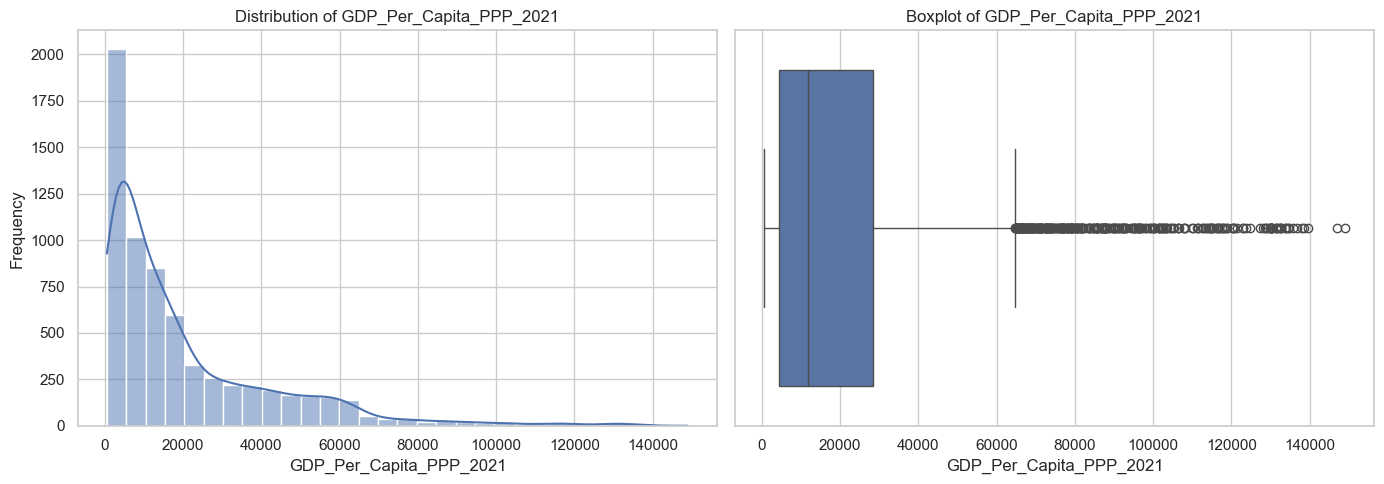

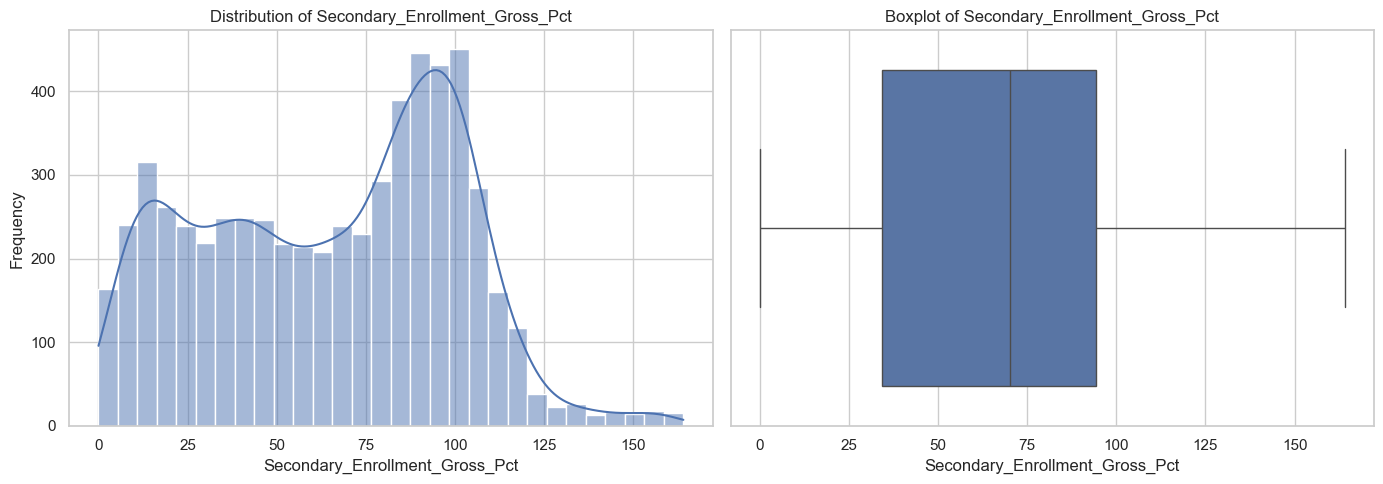

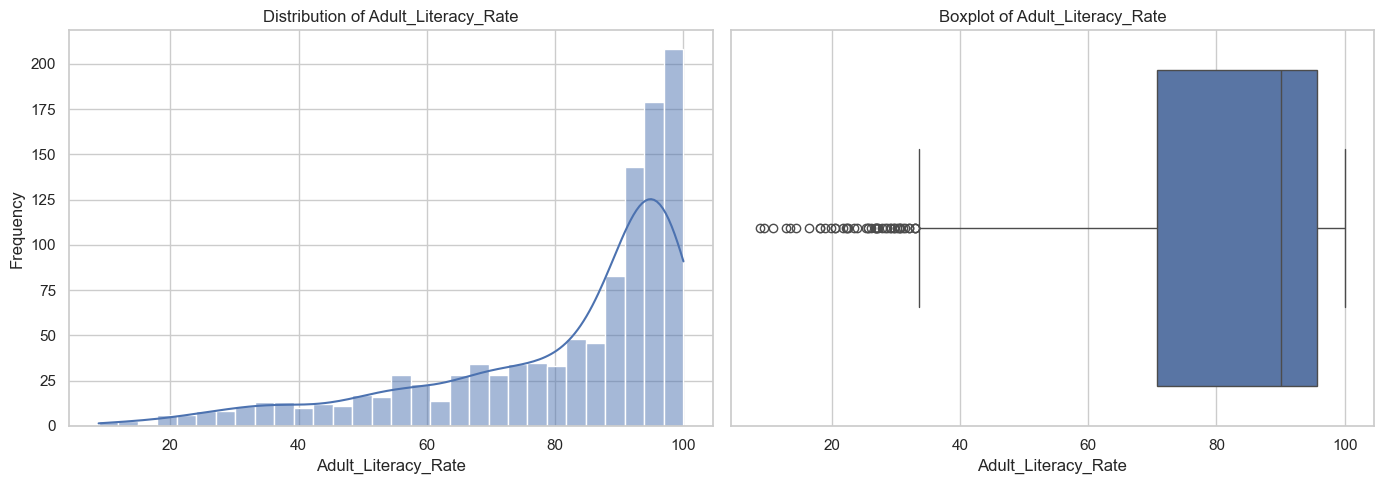

In [14]:
for indicator in distribution_indicators:
    
    data = df[indicator].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Histogram
    sns.histplot(
        data=data,
        bins=30,
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(f"Distribution of {indicator}")
    axes[0].set_xlabel(indicator)
    axes[0].set_ylabel("Frequency")

    # Boxplot
    sns.boxplot(
        x=data,
        ax=axes[1]
    )

    axes[1].set_title(f"Boxplot of {indicator}")
    axes[1].set_xlabel(indicator)

    plt.tight_layout()

    # Save chart
    chart_name = indicator.lower() + "_distribution.png"
    plt.savefig(CHARTS_DIR / chart_name, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close()

### Distribution Analysis Findings

**GDP per Capita (PPP):**
The GDP distribution is strongly right-skewed, with a skewness of 1.96. The mean (20,418.30) is considerably higher than the median (11,809.95), indicating that a relatively small number of high-income observations increase the overall average. The boxplot also reveals numerous potential high-value outliers.

**Secondary Enrollment:**
Secondary enrollment has a nearly symmetric overall distribution, with a skewness of -0.08. Its mean (65.18%) and median (70.05%) are relatively close. The distribution shows multiple peaks, suggesting variation in enrollment levels across observations. Values above 100% are retained because gross enrollment ratios can legitimately exceed 100%.

**Adult Literacy Rate:**
Adult literacy is negatively skewed, with a skewness of -1.35. Most observations are concentrated at higher literacy levels, while a smaller number of lower values extend the distribution to the left. The boxplot identifies several potential low-value outliers, which are retained because they may represent genuine differences between countries.

**Outlier Handling:**
Potential outliers were identified using visual inspection of histograms and boxplots. No observations were removed, since extreme values may represent genuine socioeconomic differences rather than data errors.

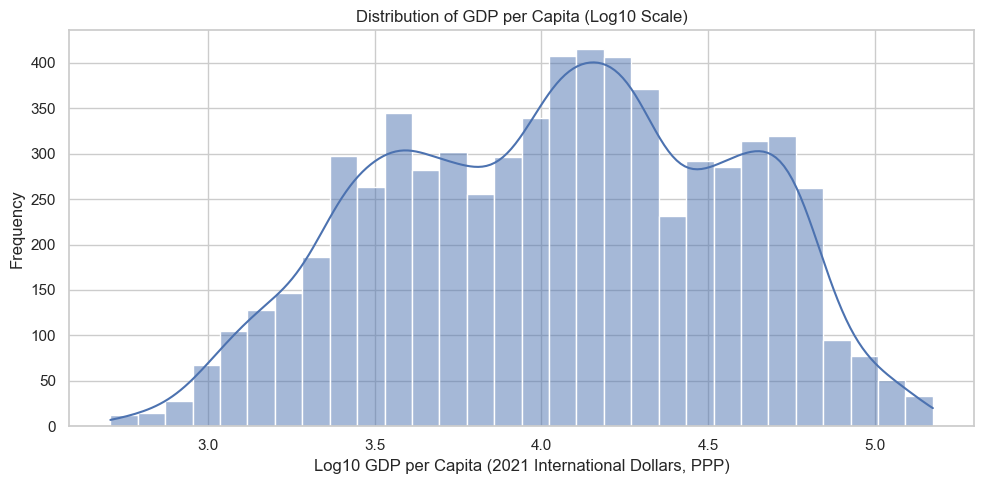

In [15]:
gdp_data = df["GDP_Per_Capita_PPP_2021"].dropna()

plt.figure(figsize=(10, 5))

sns.histplot(
    np.log10(gdp_data[gdp_data > 0]),
    bins=30,
    kde=True
)

plt.title("Distribution of GDP per Capita (Log10 Scale)")
plt.xlabel("Log10 GDP per Capita (2021 International Dollars, PPP)")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    CHARTS_DIR / "gdp_per_capita_log_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

## Step 3 — GDP per Capita and UHC Relationship

This section investigates the relationship between GDP per capita (PPP) and the UHC Service Coverage Index from 2000 to 2023.

Only observations with available values for both indicators are included. Spearman correlation is used to measure the direction and strength of the association without assuming a linear relationship.

GDP vs UHC Analysis
-------------------
Observations: 4450
Countries: 186
Year Range: 2000 - 2023
Spearman Correlation: 0.8628
P-value: 0.0


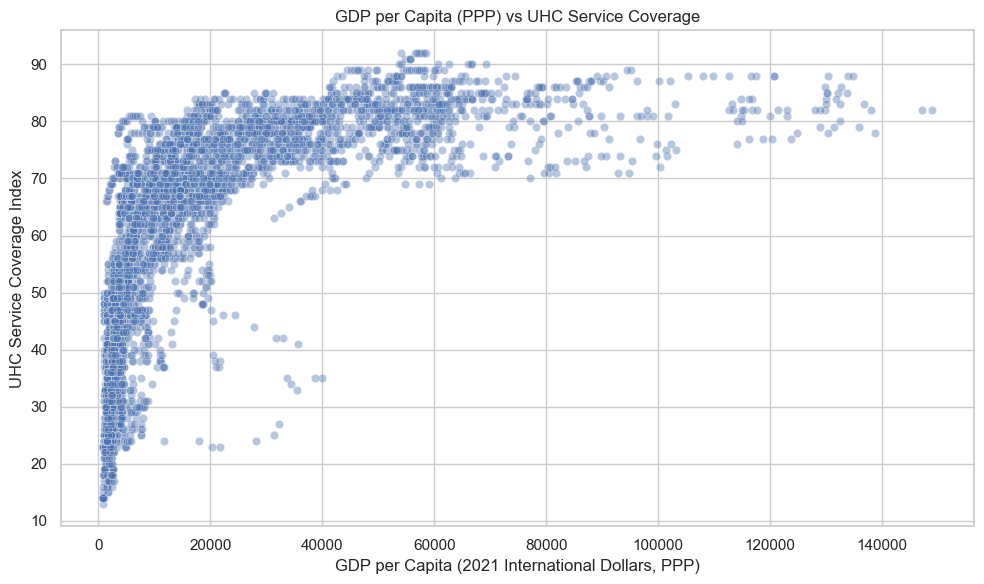

In [16]:
# Select observations from 2000 to 2023
gdp_uhc = analysis_df[
    analysis_df["GDP_Per_Capita_PPP_2021"].notna() &
    analysis_df["UHC_Service_Coverage_Index"].notna()
].copy()

# Calculate Spearman correlation
correlation, p_value = stats.spearmanr(
    gdp_uhc["GDP_Per_Capita_PPP_2021"],
    gdp_uhc["UHC_Service_Coverage_Index"]
)

print("GDP vs UHC Analysis")
print("-------------------")
print("Observations:", len(gdp_uhc))
print("Countries:", gdp_uhc["ISO3"].nunique())
print("Year Range:", gdp_uhc["Year"].min(), "-", gdp_uhc["Year"].max())
print("Spearman Correlation:", round(correlation, 4))
print("P-value:", p_value)

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=gdp_uhc,
    x="GDP_Per_Capita_PPP_2021",
    y="UHC_Service_Coverage_Index",
    alpha=0.4
)

plt.title("GDP per Capita (PPP) vs UHC Service Coverage")
plt.xlabel("GDP per Capita (2021 International Dollars, PPP)")
plt.ylabel("UHC Service Coverage Index")

plt.tight_layout()

plt.savefig(
    CHARTS_DIR / "uhc_vs_gdp_per_capita_ppp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### GDP per Capita and UHC Relationship

The analysis included 4,450 paired observations across 186 countries from 2000 to 2023.

Spearman's rank correlation coefficient was 0.8628, indicating a very strong positive association between GDP per capita (PPP) and the UHC Service Coverage Index.

The p-value was extremely small (below 0.001), indicating that the observed association is statistically significant.

These findings suggest that countries with higher GDP per capita generally tend to have higher UHC service coverage. However, this association does not establish causation, as other economic, social, and institutional factors may also influence healthcare coverage.

## Step 4 — Secondary Enrollment and UHC Relationship

This section examines the association between secondary school enrollment and the UHC Service Coverage Index from 2000 to 2023.

Only observations with available values for both indicators are included. Spearman correlation is used to evaluate the direction and strength of the association.

Secondary Enrollment vs UHC Analysis
-------------------------------------
Observations: 3304
Countries: 190
Year Range: 2000 - 2023
Spearman Correlation: 0.8262
P-value: 0.0


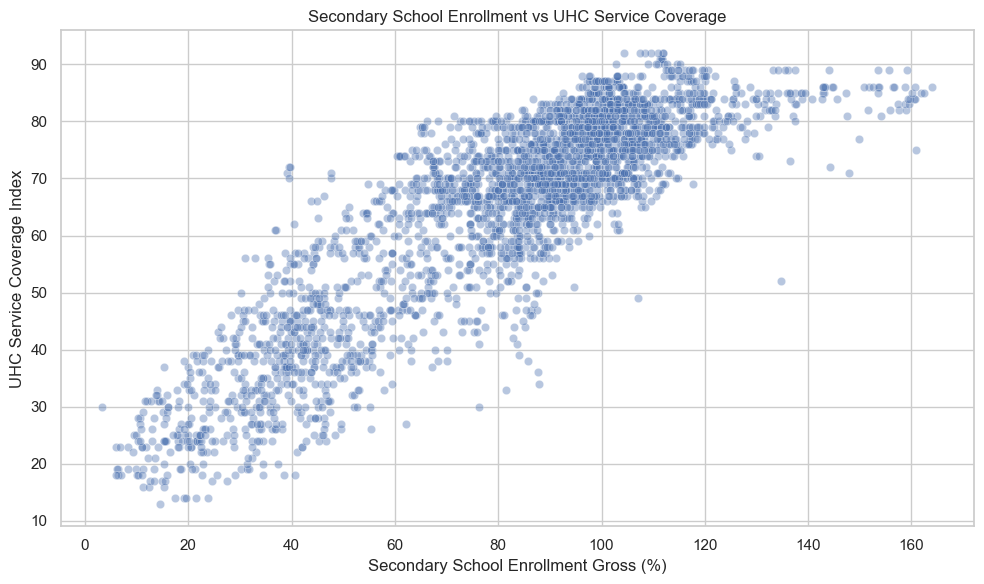

In [17]:
# Select observations with both indicators available
education_uhc = analysis_df[
    analysis_df["Secondary_Enrollment_Gross_Pct"].notna() &
    analysis_df["UHC_Service_Coverage_Index"].notna()
].copy()

# Calculate Spearman correlation
correlation, p_value = stats.spearmanr(
    education_uhc["Secondary_Enrollment_Gross_Pct"],
    education_uhc["UHC_Service_Coverage_Index"]
)

print("Secondary Enrollment vs UHC Analysis")
print("-------------------------------------")
print("Observations:", len(education_uhc))
print("Countries:", education_uhc["ISO3"].nunique())
print("Year Range:", education_uhc["Year"].min(), "-", education_uhc["Year"].max())
print("Spearman Correlation:", round(correlation, 4))
print("P-value:", p_value)

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=education_uhc,
    x="Secondary_Enrollment_Gross_Pct",
    y="UHC_Service_Coverage_Index",
    alpha=0.4
)

plt.title("Secondary School Enrollment vs UHC Service Coverage")
plt.xlabel("Secondary School Enrollment Gross (%)")
plt.ylabel("UHC Service Coverage Index")

plt.tight_layout()

plt.savefig(
    CHARTS_DIR / "uhc_vs_secondary_enrollment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Secondary Enrollment and UHC Relationship

The analysis included 3,304 paired observations across 190 countries from 2000 to 2023.

Spearman's rank correlation coefficient was 0.8262, indicating a very strong positive association between secondary school enrollment and the UHC Service Coverage Index.

The p-value was extremely small (below 0.001), indicating that the observed association is statistically significant.

This suggests that observations with higher secondary school enrollment rates generally tend to have higher UHC service coverage. However, this relationship does not establish causation, and other socioeconomic and institutional factors may influence both indicators.

## Step 5 — Adult Literacy and UHC Relationship

This section investigates the association between adult literacy rates and the UHC Service Coverage Index from 2000 to 2023.

Only observations with available values for both indicators are included. Due to the limited availability of adult literacy data, the results should be interpreted with particular attention to sample size and representativeness.

Spearman correlation is used to evaluate the direction and strength of the association.

Adult Literacy vs UHC Analysis
--------------------------------
Observations: 882
Countries: 151
Year Range: 2000 - 2023
Spearman Correlation: 0.6794
P-value: 2.0282752657891046e-120


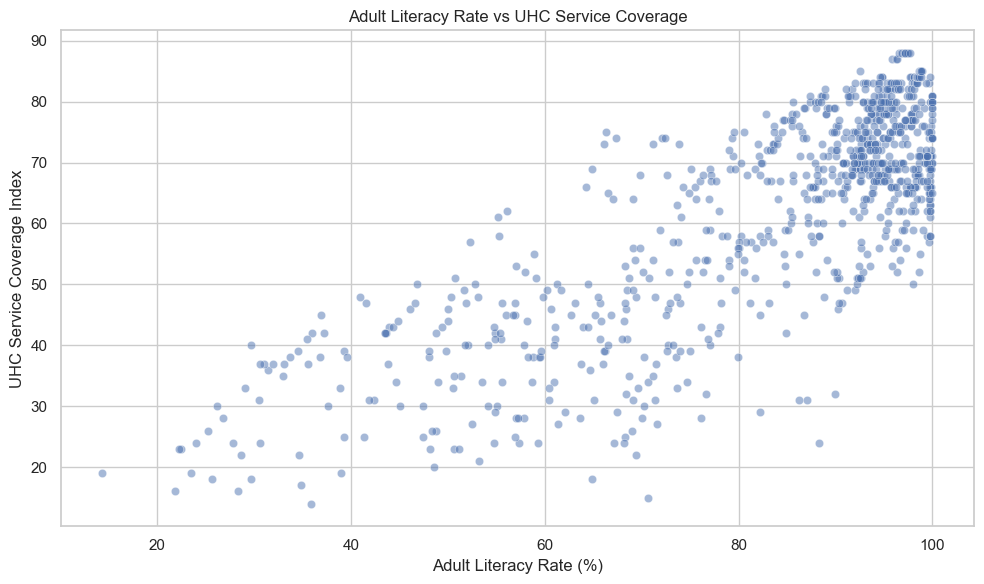

In [18]:
# Select observations with both indicators available
literacy_uhc = analysis_df[
    analysis_df["Adult_Literacy_Rate"].notna() &
    analysis_df["UHC_Service_Coverage_Index"].notna()
].copy()

# Calculate Spearman correlation
correlation, p_value = stats.spearmanr(
    literacy_uhc["Adult_Literacy_Rate"],
    literacy_uhc["UHC_Service_Coverage_Index"]
)

print("Adult Literacy vs UHC Analysis")
print("--------------------------------")
print("Observations:", len(literacy_uhc))
print("Countries:", literacy_uhc["ISO3"].nunique())
print("Year Range:", literacy_uhc["Year"].min(), "-", literacy_uhc["Year"].max())
print("Spearman Correlation:", round(correlation, 4))
print("P-value:", p_value)

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=literacy_uhc,
    x="Adult_Literacy_Rate",
    y="UHC_Service_Coverage_Index",
    alpha=0.5
)

plt.title("Adult Literacy Rate vs UHC Service Coverage")
plt.xlabel("Adult Literacy Rate (%)")
plt.ylabel("UHC Service Coverage Index")

plt.tight_layout()

plt.savefig(
    CHARTS_DIR / "uhc_vs_adult_literacy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Adult Literacy and UHC Relationship

The analysis included 882 paired observations across 151 countries from 2000 to 2023.

Spearman's rank correlation coefficient was 0.6794, indicating a strong positive association between adult literacy rates and the UHC Service Coverage Index.

The p-value was approximately 2.03 × 10⁻¹²⁰, indicating a statistically significant association under the assumptions of the correlation test.

Although the association is positive, it is weaker than the associations observed for GDP per capita and secondary school enrollment.

An important limitation is the restricted availability of adult literacy data. Only 882 paired observations were available, compared with 4,450 for GDP and 3,304 for secondary enrollment. Therefore, the literacy results may be less representative of the full set of countries and years.

The findings indicate an association, not a causal relationship.

## Step 6 — Socioeconomic Trends Over Time

This section examines yearly trends in GDP per capita (PPP) and the UHC Service Coverage Index from 2000 to 2023.

Yearly means and medians are calculated using available observations for each indicator. The number of countries contributing data is also reported for every year.

The analysis additionally compares both indicators in the latest year with available paired observations.

In [19]:
# Prepare yearly data for GDP and UHC
yearly_trends = analysis_df.groupby("Year").agg(
    GDP_Mean=("GDP_Per_Capita_PPP_2021", "mean"),
    GDP_Median=("GDP_Per_Capita_PPP_2021", "median"),
    GDP_Countries=("GDP_Per_Capita_PPP_2021",
                   lambda x: analysis_df.loc[x.index, "ISO3"][x.notna()].nunique()),

    UHC_Mean=("UHC_Service_Coverage_Index", "mean"),
    UHC_Median=("UHC_Service_Coverage_Index", "median"),
    UHC_Countries=("UHC_Service_Coverage_Index",
                   lambda x: analysis_df.loc[x.index, "ISO3"][x.notna()].nunique())
).reset_index()

display(yearly_trends.round(2))

,Year,GDP_Mean,GDP_Median,GDP_Countries,UHC_Mean,UHC_Median,UHC_Countries
0,2000,"17,984.10","9,981.63",185,55.34,63.00,195
1,2001,"18,193.53","9,748.03",185,55.76,64.00,195
2,2002,"18,437.51","9,869.71",185,56.25,65.00,195
3,2003,"18,859.65","9,902.20",185,56.78,65.00,195
4,2004,"19,603.14","10,263.81",185,57.41,66.00,195
5,2005,"20,186.69","10,660.20",185,58.16,67.00,195
6,2006,"20,986.40","10,983.92",185,59.26,67.00,195
7,2007,"21,622.07","11,613.92",185,60.10,67.00,195
8,2008,"21,759.41","11,990.20",185,60.77,67.00,195
9,2009,"20,881.48","12,033.91",185,61.47,68.00,195


In [20]:
# Find the latest year with paired GDP and UHC observations
paired_gdp_uhc = analysis_df.dropna(
    subset=[
        "GDP_Per_Capita_PPP_2021",
        "UHC_Service_Coverage_Index"
    ]
).copy()

latest_common_year = paired_gdp_uhc["Year"].max()

latest_year_data = paired_gdp_uhc[
    paired_gdp_uhc["Year"] == latest_common_year
]

print("Latest Common Year:", latest_common_year)
print("Paired Observations:", len(latest_year_data))
print("Countries:", latest_year_data["ISO3"].nunique())
print("Mean GDP:", round(latest_year_data["GDP_Per_Capita_PPP_2021"].mean(), 2))
print("Median GDP:", round(latest_year_data["GDP_Per_Capita_PPP_2021"].median(), 2))
print("Mean UHC:", round(latest_year_data["UHC_Service_Coverage_Index"].mean(), 2))
print("Median UHC:", round(latest_year_data["UHC_Service_Coverage_Index"].median(), 2))

Latest Common Year: 2023
Paired Observations: 185
Countries: 185
Mean GDP: 25399.59
Median GDP: 16222.86
Mean UHC: 68.49
Median UHC: 72.0


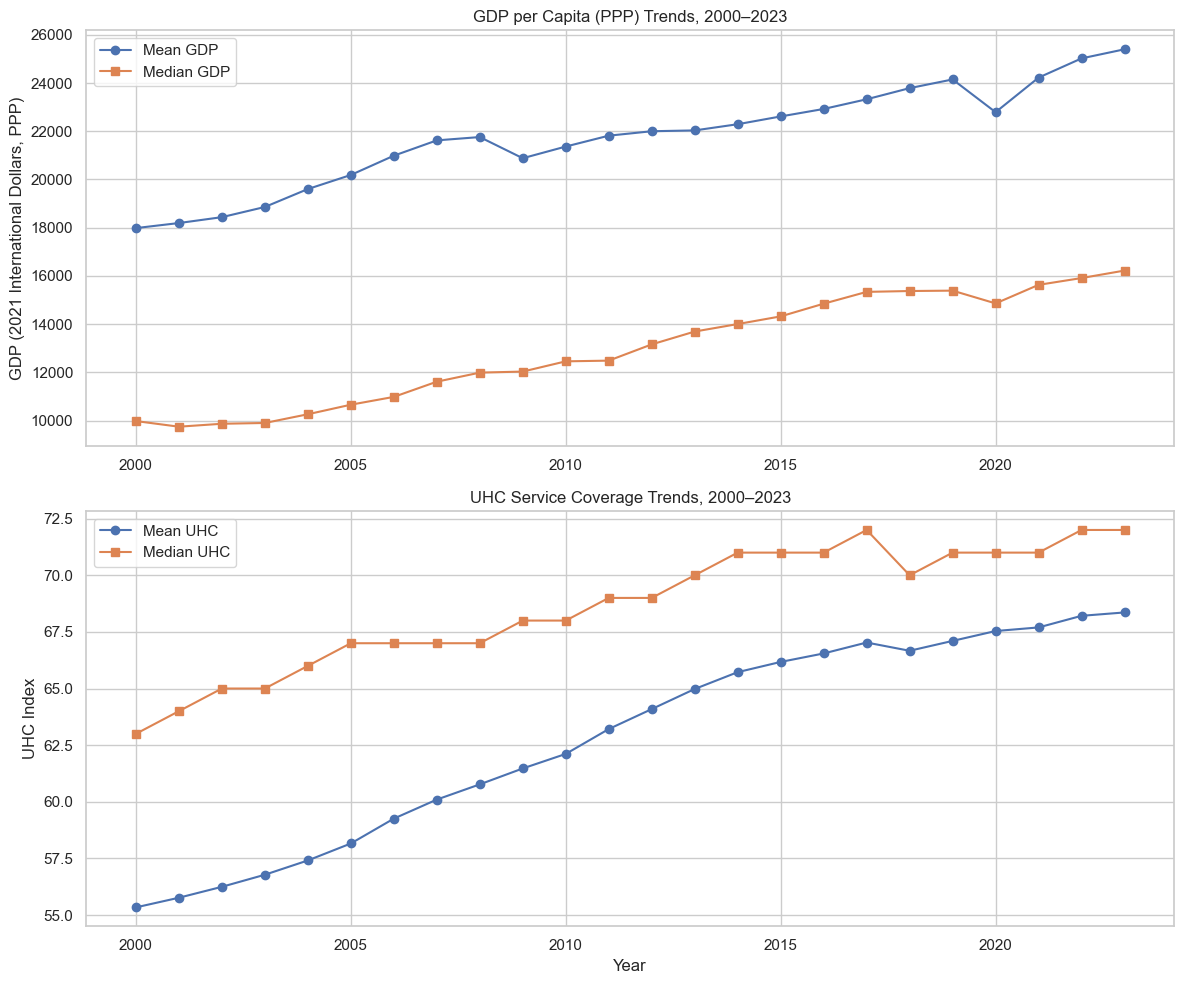

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# GDP trend
axes[0].plot(
    yearly_trends["Year"],
    yearly_trends["GDP_Mean"],
    marker="o",
    label="Mean GDP"
)

axes[0].plot(
    yearly_trends["Year"],
    yearly_trends["GDP_Median"],
    marker="s",
    label="Median GDP"
)

axes[0].set_title("GDP per Capita (PPP) Trends, 2000–2023")
axes[0].set_ylabel("GDP (2021 International Dollars, PPP)")
axes[0].legend()

# UHC trend
axes[1].plot(
    yearly_trends["Year"],
    yearly_trends["UHC_Mean"],
    marker="o",
    label="Mean UHC"
)

axes[1].plot(
    yearly_trends["Year"],
    yearly_trends["UHC_Median"],
    marker="s",
    label="Median UHC"
)

axes[1].set_title("UHC Service Coverage Trends, 2000–2023")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("UHC Index")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    CHARTS_DIR / "socioeconomic_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Socioeconomic Trends Over Time

Between 2000 and 2023, the average GDP per capita (PPP) increased from 17,984.10 to 25,399.59, representing an increase of approximately 41.2%.

The median GDP also increased from 9,981.63 to 16,222.86, suggesting an overall improvement in the middle of the observed GDP distribution.

The average UHC Service Coverage Index increased from 55.34 in 2000 to 68.36 in 2023, while the median increased from 63 to 72. This indicates an overall improvement in healthcare service coverage over the study period.

GDP experienced noticeable declines in 2009 and 2020, while UHC showed a relatively gradual upward trend, with a small decline in 2018.

In 2023, the latest year with paired GDP and UHC observations, 185 countries were included. Their mean GDP was 25,399.59, while their mean UHC index was 68.49.

The yearly averages are calculated independently for each indicator using available observations. Therefore, differences in country coverage should be considered when interpreting trends. These aggregate trends describe changes over time but do not establish a causal relationship between GDP and UHC.

## Step 7 — Final Insights and Interpretation

This section summarizes the main findings from the socioeconomic and education analysis and discusses the limitations of the available data.

### Key Findings

1. GDP per capita (PPP) showed the strongest positive association with UHC, with a Spearman correlation of 0.8628.
2. Secondary school enrollment also showed a very strong positive association with UHC, with a correlation of 0.8262.
3. Adult literacy showed a strong positive association with UHC, with a correlation of 0.6794.
4. Both GDP per capita and UHC generally increased between 2000 and 2023.
5. Adult literacy results should be interpreted cautiously because of the limited availability of observations.

### Data Limitations

- Adult literacy had 91.43% missing observations.
- UHC had 63.59% missing observations.
- GDP and secondary enrollment also had substantial missing data.
- The number of available countries varies across indicators and years.
- Repeated country-year observations may not be statistically independent.
- Correlation does not establish causation.

### Dashboard Insights

- GDP per capita has the strongest observed association with UHC.
- Secondary school enrollment is also strongly associated with healthcare coverage.
- Adult literacy has a positive association with UHC, but its analysis is based on a much smaller sample.

### Conclusion

The analysis identifies strong positive associations between socioeconomic and educational indicators and UHC service coverage. GDP per capita and secondary school enrollment showed the strongest associations. However, data availability, country coverage, and the observational nature of the analysis should be considered when interpreting these findings.

In [22]:
# 1. Create the summary CSV

summary_data = [
    {
        "Comparison": "GDP per Capita vs UHC",
        "Observations": 4450,
        "Countries": 186,
        "Start Year": 2000,
        "End Year": 2023,
        "Spearman Correlation": 0.8628,
        "P-value": "< 0.001",
        "Interpretation": "Very strong positive association"
    },
    {
        "Comparison": "Secondary Enrollment vs UHC",
        "Observations": 3304,
        "Countries": 190,
        "Start Year": 2000,
        "End Year": 2023,
        "Spearman Correlation": 0.8262,
        "P-value": "< 0.001",
        "Interpretation": "Very strong positive association"
    },
    {
        "Comparison": "Adult Literacy vs UHC",
        "Observations": 882,
        "Countries": 151,
        "Start Year": 2000,
        "End Year": 2023,
        "Spearman Correlation": 0.6794,
        "P-value": "2.03e-120",
        "Interpretation": "Strong positive association"
    }
]

summary_df = pd.DataFrame(summary_data)

summary_path = OUTPUT_DIR / "socioeconomic_analysis_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("Summary CSV saved:", summary_path)


# 2. Create the final Markdown report

report = """
# Socioeconomic & Education Analysis Report

## 1. Project Overview

This analysis investigates the relationships between socioeconomic and educational indicators and Universal Health Coverage (UHC) across countries and years.

The main indicators examined are GDP per capita (PPP), secondary school enrollment, and adult literacy rate.

## 2. Dataset Overview

- Total observations: 12,855
- Total columns: 27
- Countries: 196
- Dataset year range: 1960–2025
- Analysis period: 2000–2023
- Duplicate country-year records: 0

## 3. Data Availability

| Indicator | Available | Missing | Missing (%) |
|---|---:|---:|---:|
| GDP per Capita (PPP) | 6,630 | 6,225 | 48.42% |
| Secondary Enrollment | 6,023 | 6,832 | 53.15% |
| Adult Literacy | 1,102 | 11,753 | 91.43% |
| UHC Service Coverage | 4,680 | 8,175 | 63.59% |

Adult literacy has particularly limited data availability, which affects the representativeness of its analysis.

## 4. Distribution Analysis

### GDP per Capita (PPP)

GDP has a positively skewed distribution (skewness = 1.96). Its mean is 20,418.30, while its median is 11,809.95. This indicates that high-value observations pull the mean upward.

### Secondary Enrollment

Secondary enrollment has a nearly symmetric overall distribution (skewness = -0.08). Its mean is 65.18%, and its median is 70.05%.

Gross enrollment ratios above 100% were retained because they can be legitimate values.

### Adult Literacy

Adult literacy has a negatively skewed distribution (skewness = -1.35). Most available observations are concentrated at higher literacy levels.

Potential outliers were retained because extreme values may represent genuine differences between countries.

## 5. Correlation Analysis

All comparisons use pairwise available observations from 2000 to 2023.

| Comparison | Observations | Countries | Spearman Correlation |
|---|---:|---:|---:|
| GDP vs UHC | 4,450 | 186 | 0.8628 |
| Secondary Enrollment vs UHC | 3,304 | 190 | 0.8262 |
| Adult Literacy vs UHC | 882 | 151 | 0.6794 |

### GDP and UHC

A very strong positive association was observed (Spearman = 0.8628, p < 0.001).

### Secondary Enrollment and UHC

A very strong positive association was observed (Spearman = 0.8262, p < 0.001).

### Adult Literacy and UHC

A strong positive association was observed (Spearman = 0.6794, p < 0.001).

The literacy comparison has a substantially smaller sample, so its results require additional caution.

These correlations describe associations and do not establish causal relationships. Repeated observations from the same countries may also affect the assumptions of conventional significance tests.

## 6. Trends Over Time

Between 2000 and 2023:

- Mean GDP per capita increased from 17,984.10 to 25,399.59, approximately 41.2%.
- Median GDP increased from 9,981.63 to 16,222.86, approximately 62.5%.
- Mean UHC increased from 55.34 to 68.36.
- Median UHC increased from 63 to 72.

In 2023, 185 countries had paired GDP and UHC observations. Their mean GDP was 25,399.59 and their mean UHC index was 68.49.

Yearly averages use the available observations for each indicator independently. Therefore, the number of contributing countries may differ between indicators.

## 7. Key Dashboard Insights

1. GDP per capita showed the strongest observed association with UHC.
2. Secondary school enrollment also showed a very strong positive association with UHC.
3. Adult literacy was positively associated with UHC, but its results were based on substantially fewer observations.
4. Both GDP and UHC generally increased during the analysis period.

## 8. Limitations

- Missing values vary substantially across indicators.
- Adult literacy data has 91.43% missing observations.
- Country coverage changes across years and indicators.
- The analysis is observational and cannot establish causation.
- Repeated country-year observations may not be independent.
- Potential outliers were retained rather than removed without justification.

## 9. Conclusion

The analysis found positive associations between GDP per capita, secondary school enrollment, adult literacy, and UHC service coverage.

GDP per capita showed the strongest association, followed by secondary school enrollment and adult literacy.

These findings highlight the importance of socioeconomic and educational context when examining healthcare coverage. However, missing data, sample representativeness, and the observational nature of the analysis must be considered when interpreting the results.
"""

report_path = OUTPUT_DIR / "socioeconomic_analysis_report.md"

report_path.write_text(report, encoding="utf-8")

print("Final report saved:", report_path)


# 3. Confirm generated files

print("\nGenerated deliverables:")
print("- socioeconomic_analysis_summary.csv:", summary_path.exists())
print("- socioeconomic_analysis_report.md:", report_path.exists())

Summary CSV saved: e:\Aya\Socioeconomic_Education_Analysis\outputs\socioeconomic_analysis_summary.csv
Final report saved: e:\Aya\Socioeconomic_Education_Analysis\outputs\socioeconomic_analysis_report.md

Generated deliverables:
- socioeconomic_analysis_summary.csv: True
- socioeconomic_analysis_report.md: True
